<a href="https://colab.research.google.com/github/Govind-2004/Computer_Vision_Parallel_Project_Group_2/blob/main/Group_2_CNN_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries

In [67]:
import os
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt


import tensorflow as tf

#VGG16
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [68]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Read Dataset

In [69]:
# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# data path
train_dir = "/content/drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training"
test_dir = "/content/drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Testing"

In [70]:
# Load train dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 5610 files belonging to 4 classes.
Using 4488 files for training.


In [71]:
# Validation dataset

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    seed = 42
)

Found 5610 files belonging to 4 classes.
Using 1122 files for validation.


In [72]:
# Inference: validation dataset used monitor the model while it is learning.

In [73]:
# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle = False
)

Found 1604 files belonging to 4 classes.


# EDA

## Class Distribution

In [74]:
# Verifying dataset classes
class_names = train_dataset.class_names
print('classes:', class_names)

classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [75]:
# Image count in each class in training dataset
print("Training Dataset")

for cls in class_names:
    count = len(os.listdir(os.path.join(train_dir, cls)))
    print(f"{cls}: {count} images")


print('\n')

# Image count in each class in test dataset
print("Testing Dataset")

for cls in class_names:
    count = len(os.listdir(os.path.join(test_dir, cls)))
    print(f"{cls}: {count} images")

Training Dataset
glioma: 1400 images
meningioma: 1400 images
notumor: 1410 images
pituitary: 1400 images


Testing Dataset
glioma: 403 images
meningioma: 400 images
notumor: 401 images
pituitary: 400 images


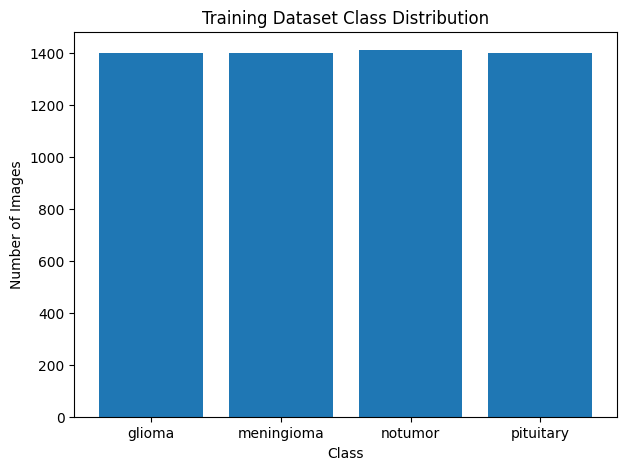

In [76]:
# class distribution plot

train_counts = [
    len(os.listdir(os.path.join(train_dir, cls)))
    for cls in class_names
]

plt.figure(figsize=(7,5))
plt.bar(class_names, train_counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

In [77]:
# The dataset is balanced.(only negligible difference)

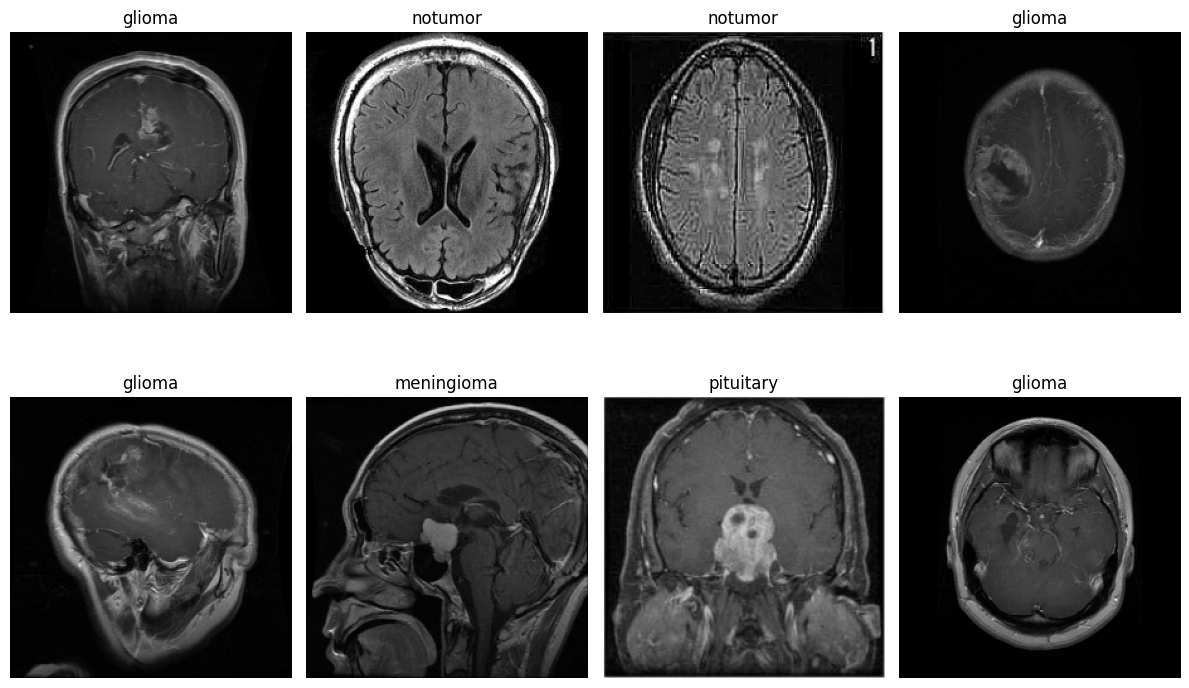

In [78]:
# Displaying Sample Images
images, labels = next(iter(train_dataset))

plt.figure(figsize=(12,8))

for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [79]:
# Inference: Ensured that dataset labels corresponded to their respective class folders

In [80]:
images.shape

TensorShape([32, 224, 224, 3])

# Data Preprocessing

## Normalizing

In [81]:
# Before normalizing
images, labels = next(iter(train_dataset))
print("Minimum Pixel Value:", images.numpy().min())
print("Maximum Pixel Value:", images.numpy().max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 255.0


In [82]:
# Normalizing

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [83]:
# After normalizing
images, labels = next(iter(train_dataset))
print("Minimum Pixel Value:", images.numpy().min())
print("Maximum Pixel Value:", images.numpy().max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [84]:
# Inference: The Rescaling(1./255) layer, the pixel values were normalized to the range 0 to 1

## Data Augmentation

In [85]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [86]:
# To increases image diversity, some random transformations are applied:

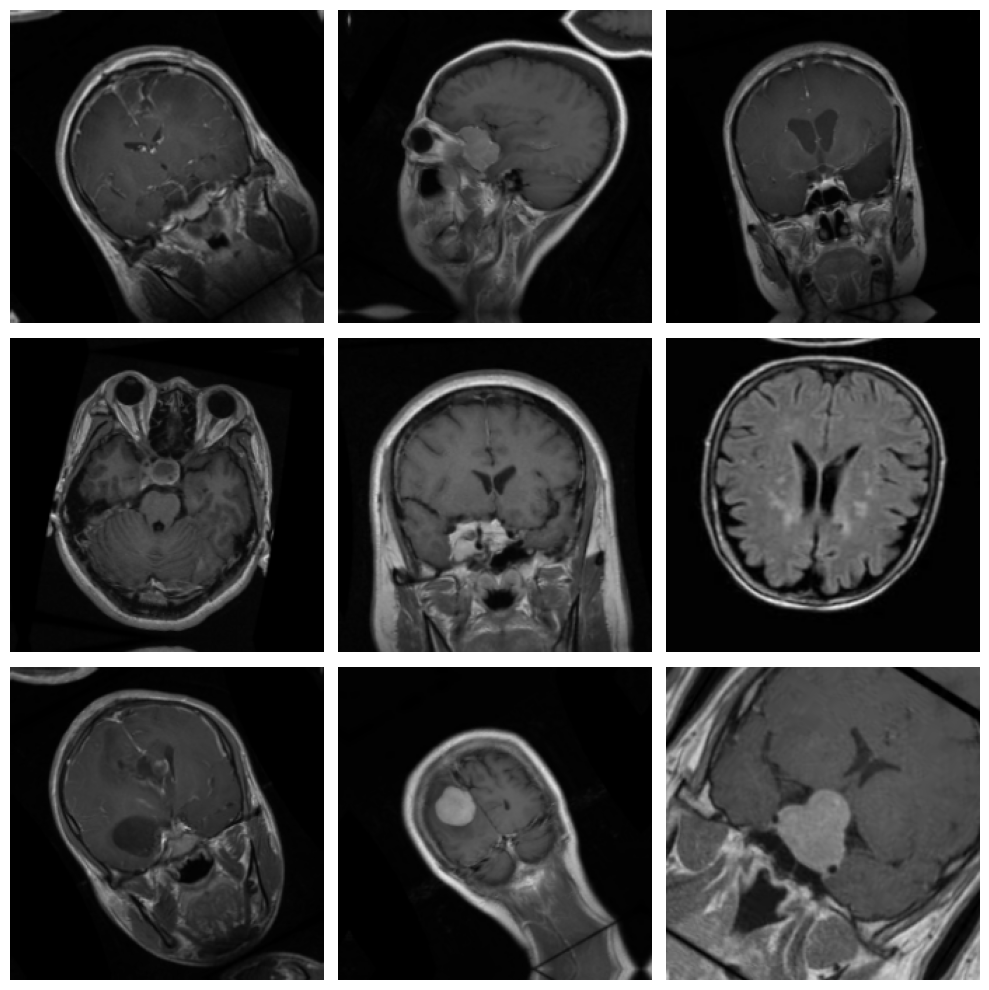

In [87]:
# Visualize augmented images
images, labels = next(iter(train_dataset))

plt.figure(figsize=(10,10))

for i in range(9):
    augmented_image = data_augmentation(images)[i]

    plt.subplot(3,3,i+1)
    plt.imshow(augmented_image.numpy())
    plt.axis("off")

plt.tight_layout()
plt.show()

# Model Building


##CNN

In [88]:
# Building the CNN model

model = tf.keras.Sequential([

    tf.keras.layers.Conv2D(
        32, (3,3),
        activation='relu',
        input_shape=(IMG_HEIGHT, IMG_WIDTH,  3)
    ),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(
        64, (3,3),
        activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Conv2D(
        128, (3,3),
        activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2,2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(len(class_names), activation='softmax')

])

### Compile Model

In [89]:
# Compile the CNN Model

model.compile(optimizer = 'adam',                         # Adam optimizer for efficient weight updates
              loss = 'sparse_categorical_crossentropy',   # Suitable for multi-class classification with integer labels
              metrics = ['accuracy'])                     # Tracks classification accuracy during training

### Train Model

In [90]:
# Begin Model Training

print("\n Started Training.....")


 Started Training.....


In [91]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_brain_tumor_model.keras",
    monitor='val_loss',
    save_best_only=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=50,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 27s 170ms/step - accuracy: 0.7043 - loss: 0.7385 - val_accuracy: 0.7540 - val_loss: 0.5549
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 36s 150ms/step - accuracy: 0.8549 - loss: 0.3820 - val_accuracy: 0.8930 - val_loss: 0.2993
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 23s 162ms/step - accuracy: 0.9104 - loss: 0.2341 - val_accuracy: 0.8975 - val_loss: 0.2732
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 23s 157ms/step - accuracy: 0.9385 - loss: 0.1614 - val_accuracy: 0.9216 - val_loss: 0.2007
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 22s 152ms/step - accuracy: 0.9594 - loss: 0.1120 - val_accuracy: 0.9278 - val_loss: 0.2294
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 20s 142ms/step - accuracy: 0.9757 - loss: 0.0730 - val_accuracy: 0.9287 - val_loss: 0.2144
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 23s 161ms/step - accuracy: 0.9770 - loss: 0.0677 - val_accuracy: 0.9349 - val_loss: 0.1955
Epoch 8/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 21s 147ms/step - accuracy: 0.9804 - loss: 0

### Evaluation

In [92]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.2f}")
print(f"Test Accuracy: {test_accuracy:.2f}")

print("\nFinal Training Accuracy :", history.history['accuracy'][-1])
print("Final Validation Accuracy :", history.history['val_accuracy'][-1])

print("\nFinal Training Loss :", history.history['loss'][-1])
print("Final Validation Loss :", history.history['val_loss'][-1])


51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - accuracy: 0.8703 - loss: 1.1997
Test Loss: 1.20
Test Accuracy: 0.87

Final Training Accuracy : 0.9895276427268982
Final Validation Accuracy : 0.9429590106010437

Final Training Loss : 0.03219403326511383
Final Validation Loss : 0.2516876757144928


###Save Model

In [93]:
# Saving the CNN model

model.save("brain_tumor_cnn_v1.keras")

In [94]:
# Confirmation Message

print("\n Model saved as brain_tumor_cnn_v1.keras")


 Model saved as brain_tumor_cnn_v1.keras


### Plot Accuracy & Loss Graphs

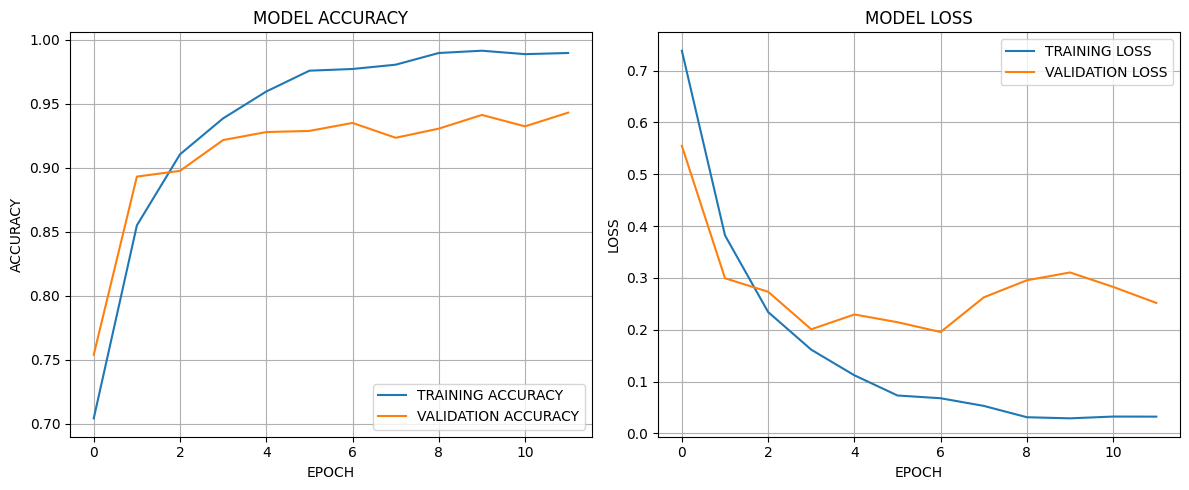

In [95]:
# Visualize Model Performance

plt.figure(figsize=(12,5))

# Accuracy Graph
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='TRAINING ACCURACY')
plt.plot(history.history['val_accuracy'], label='VALIDATION ACCURACY')
plt.title('MODEL ACCURACY')
plt.xlabel('EPOCH')
plt.ylabel('ACCURACY')
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='TRAINING LOSS')
plt.plot(history.history['val_loss'], label='VALIDATION LOSS')
plt.title('MODEL LOSS')
plt.xlabel('EPOCH')
plt.ylabel('LOSS')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Predict Test Image

In [96]:
# Load the previously saved CNN model from the .keras file

model = tf.keras.models.load_model("brain_tumor_cnn_v1.keras")

In [97]:
# Search for the test image in Google Drive

!find

Streaming output truncated to the last 5000 lines.
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_953.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_939.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_965.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_946.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_963.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_950.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_95.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_942.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_94.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_948.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_95

In [98]:
# Define the file path of the image to be used for prediction.

test_image_path = "/content/drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Testing/meningioma/Te-aug-me_100.jpg"

In [99]:
# Load and Preprocess Test Image

if not os.path.exists(test_image_path):
    raise FileNotFoundError(f"Test image not found: {test_image_path}")         # Check whether the test image exists


# Read image using OpenCv
image = cv2.imread(test_image_path)

# Original
display_image = image.copy()

# Resize for model
image = cv2.resize(image, (IMG_HEIGHT, IMG_WIDTH))

# Convert BRG to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Normalize
image = image/255.0

# Add batch dimension
image = np.expand_dims(image, axis = 0)

#Predict
prediction = model.predict(image)


predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = np.max(prediction) * 100                                           # Predict Brain Tumor Class

print(f'\n Prediction: {predicted_class}')
print(f'\n Confidence: {confidence:.2f}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step

 Prediction: meningioma

 Confidence: 99.87


###Display Result

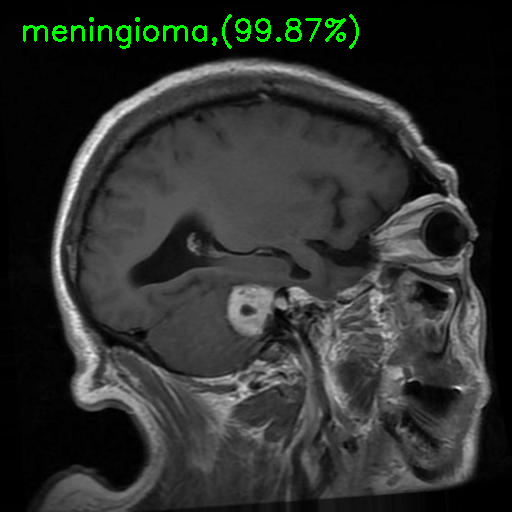

In [100]:
# Display Prediction on Image

text = f'{predicted_class},({confidence:.2f}%)'       # Create the prediction label with confidence score

cv2.putText(
    display_image,
    text,(20,40),
    cv2.FONT_HERSHEY_SIMPLEX,                         # Draw the prediction text on the image
    1,(0,255,0),
    2
)
cv2_imshow(display_image)                            # Display the predicted image

##VGG16

In [101]:
# base vgg model building
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [102]:
v_model = Sequential([

    data_augmentation,

    base_model,

    tf.keras.layers.Flatten(),

    Dense(256, activation='relu'),

    Dropout(0.5),

    Dense(len(class_names), activation='softmax')

])

### Compile Model

In [103]:
# Compile the VGG Model

v_model.compile(optimizer = 'adam',
              loss = 'sparse_categorical_crossentropy',
              metrics = ['accuracy'])

### Train Model

In [104]:
# Begin Model Training

print("\n Started Training.....")


 Started Training.....


In [105]:
history = v_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 33s 219ms/step - accuracy: 0.6671 - loss: 1.0588 - val_accuracy: 0.8761 - val_loss: 0.4169
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 35s 175ms/step - accuracy: 0.7656 - loss: 0.6019 - val_accuracy: 0.8396 - val_loss: 0.4021
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accuracy: 0.7872 - loss: 0.5405 - val_accuracy: 0.8797 - val_loss: 0.3855
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - accuracy: 0.7966 - loss: 0.5051 - val_accuracy: 0.8663 - val_loss: 0.3651
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.7975 - loss: 0.5064 - val_accuracy: 0.8654 - val_loss: 0.3577


### Evaluation

In [106]:
# Evaluate the model
test_loss, test_accuracy = v_model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.2f}")
print(f"Test Accuracy: {test_accuracy:.2f}")

print("\nFinal Training Accuracy :", history.history['accuracy'][-1])
print("Final Validation Accuracy :", history.history['val_accuracy'][-1])

print("\nFinal Training Loss :", history.history['loss'][-1])
print("Final Validation Loss :", history.history['val_loss'][-1])


51/51 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 0.7731 - loss: 0.6769
Test Loss: 0.68
Test Accuracy: 0.77

Final Training Accuracy : 0.7974599003791809
Final Validation Accuracy : 0.8654189109802246

Final Training Loss : 0.5063865780830383
Final Validation Loss : 0.3576514422893524


###Save Model

In [107]:
# Saving the vgg model

v_model.save("brain_tumor_vgg_v1.keras")

In [108]:
# Confirmation Message

print("\n Model saved as brain_tumor_vgg_v1.keras")


 Model saved as brain_tumor_vgg_v1.keras


### Plot Accuracy & Loss Graphs

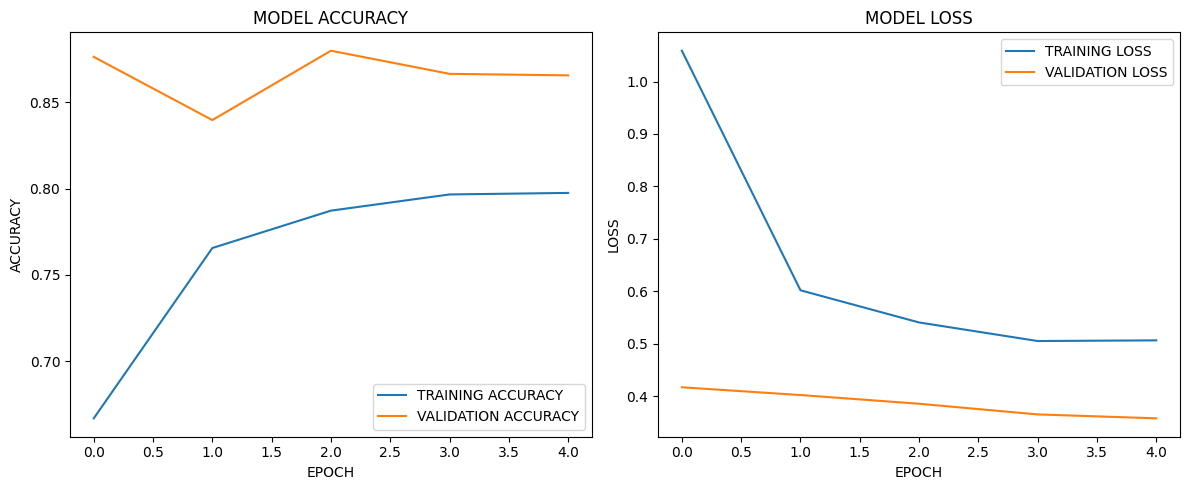

In [109]:
# Visualize Model Performance

plt.figure(figsize=(12,5))

# Accuracy Graph
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='TRAINING ACCURACY')
plt.plot(history.history['val_accuracy'], label='VALIDATION ACCURACY')
plt.title('MODEL ACCURACY')
plt.xlabel('EPOCH')
plt.ylabel('ACCURACY')
plt.legend()

# Loss Graph
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='TRAINING LOSS')
plt.plot(history.history['val_loss'], label='VALIDATION LOSS')
plt.title('MODEL LOSS')
plt.xlabel('EPOCH')
plt.ylabel('LOSS')
plt.legend()
plt.tight_layout()
plt.show()

### Predict Test Image

In [110]:
# Load the previously saved CNN model from the .keras file

model = tf.keras.models.load_model("brain_tumor_vgg_v1.keras")

In [111]:
# Search for the test image in Google Drive

!find

Streaming output truncated to the last 5000 lines.
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_953.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_939.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_965.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_946.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_963.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_950.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_95.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_942.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_94.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_948.jpg
./drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Training/notumor/Tr-no_95

In [112]:
# Define the file path of the image to be used for prediction.

test_image_path = "/content/drive/MyDrive/Colab Notebooks/Datasets /TUMOR_PROJECT/Testing/meningioma/Te-aug-me_100.jpg"

In [113]:
# Load and Preprocess Test Image

if not os.path.exists(test_image_path):
    raise FileNotFoundError(f"Test image not found: {test_image_path}")         # Check whether the test image exists


# Read image using OpenCv
image = cv2.imread(test_image_path)

# Original
display_image = image.copy()

# Resize for model
image = cv2.resize(image, (IMG_HEIGHT, IMG_WIDTH))

# Convert BRG to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Normalize
image = image/255.0

# Add batch dimension
image = np.expand_dims(image, axis = 0)

#Predict
prediction = model.predict(image)


predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = np.max(prediction) * 100                                           # Predict Brain Tumor Class

print(f'\n Prediction: {predicted_class}')
print(f'\n Confidence: {confidence:.2f}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step

 Prediction: meningioma

 Confidence: 71.72


###Display Result

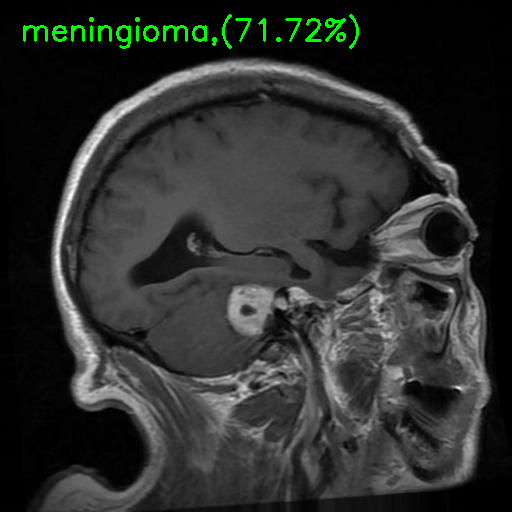

In [114]:
# Display Prediction on Image

text = f'{predicted_class},({confidence:.2f}%)'       # Create the prediction label with confidence score

cv2.putText(
    display_image,
    text,(20,40),
    cv2.FONT_HERSHEY_SIMPLEX,                         # Draw the prediction text on the image
    1,(0,255,0),
    2
)
cv2_imshow(display_image)                            # Display the predicted image